In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
df.head()
print("Shape:", df.shape)
print()
df.info()


Shape: (320, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   AdvertisingSpend_KES  320 non-null    int64 
 1   StoreVisits           320 non-null    int64 
 2   DiscountPercent       320 non-null    int64 
 3   Region                320 non-null    object
 4   CustomerSegment       320 non-null    object
 5   ProductCategory       320 non-null    object
 6   Sales_KES             320 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 17.6+ KB


## Number of columns and rows

Number of columns= 7
Number of rows= 320.

## Numeric variables.

AdverisingSpend_KES- Amount of money spend on advertisement
StoreVisits - Numerical value for store visits
Discountpercent - Discount given in percentage
Sales_KES - Sales in amount

## Categorical Variables.

Region - Location
CustomerSegment
ProductCategory- Product bought

## What one row represents.

Each row represents the customer details on what sales observation associated with advertising expenditure, store visits,discount percentage ,region, customer segment and product category.

## identify the prediction target

The prediction target is Sales_KES ,to be used to analyze the sales in different regions and diffrent products.



Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


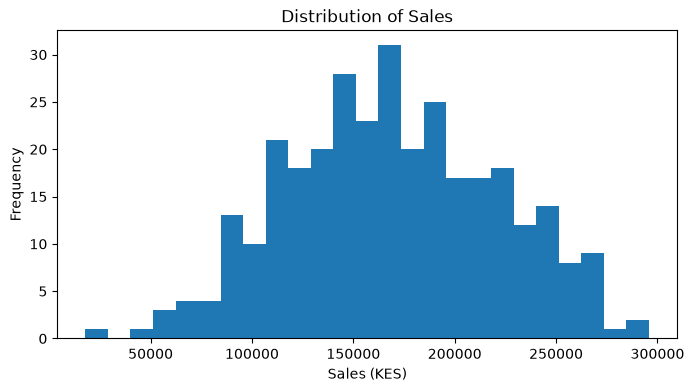

In [4]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
df["Sales_KES"].describe()
plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

## Interpretation: write 2–3 sentences on the target range, shape, and any unusual values.
Sales values range from KES 17,805 to KES 295,825, with a mean of KES 169,252.45 and a median of KES 168,462. The distribution appears potentially slightly right-skewed because the mean is higher than the median.


## Define the Analytical Task
• Business question: Can available business characteristics be used to estimate sales?


• Analytical task: supervised regression.


• Target: Sales_KES.


• Features: AdvertisingSpend_KES, StoreVisits, DiscountPercent, Region, CustomerSegment,
ProductCategory.

Objective: The aim is to build and compare regression models that use these six business characteristics to predict sales accurately.

In [5]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (320, 6)
y shape: (320,)


## Part 6 – Train/Test Split
Reserve 20% of the data as an untouched final test set. Use the training set for model
development and cross-validation. Do not repeatedly use the test set to choose the model

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


In [7]:
numeric_features = [
"AdvertisingSpend_KES",
"StoreVisits",
"DiscountPercent"
]
categorical_features = [
"Region",
"CustomerSegment",
"ProductCategory"
]

In [8]:
numeric_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
("imputer", SimpleImputer(strategy="most_frequent")),
("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
("num", numeric_pipeline, numeric_features),
("cat", categorical_pipeline, categorical_features)
])

## Why use a pipeline?
Learned preprocessing should be fitted only on training data. Keeping
preprocessing inside the pipeline helps prevent information leakage during validation.

In [10]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")
mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)
mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

A baseline gives a minimum reference level. The mean baseline predicts the training-set mean
for every case. The median baseline predicts the training-set median.

In [11]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
"Model": [name],
"MAE": [mean_absolute_error(y_true, y_pred)],
"RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
"R2": [r2_score(y_true, y_pred)]
})
mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "MedianBaseline")
pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,MedianBaseline,39146.750000,48649.470528,-0.005626


## Evaluation Metrics
• MAE: average absolute prediction error; lower is better.
• RMSE: penalizes large errors more heavily than MAE; lower is better.
• R²: how much variation in the target is explained by the model; higher is generally better.

In [12]:
linear_model = Pipeline([
("preprocess", preprocessor),
("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
linear_results = evaluate_regression(
y_test, linear_pred, "Linear Regression"
)
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


Interpretation questions: Is MAE lower than the baseline? Is RMSE lower? Is R² higher? Does the
model add useful predictive value?

Linear Regression performs better than both the mean and median baseline models. Its MAE is KES 13,757.84, which is substantially lower than the mean baseline MAE of KES 39,197.16 and the median baseline MAE of KES 39,146.75. Its RMSE is KES 17,469.69, also much lower than the mean baseline RMSE of KES 48,716.43 and the median baseline RMSE of KES 48,649.47. The model achieves an R² of 0.8703, meaning it explains approximately 87.03% of the variation in sales in the test set. Therefore, Linear Regression adds useful predictive value because it produces smaller prediction errors and explains substantially more variation in sales than either baseline model.

In [13]:
ridge_model = Pipeline([
("preprocess", preprocessor),
("model", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_results = evaluate_regression(
y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


Ridge is linear regression with regularization. It discourages very large coefficients and can
improve stability when predictors are noisy or correlated

In [14]:
tree_model = Pipeline([
("preprocess", preprocessor),
("model", DecisionTreeRegressor(
max_depth=4,
min_samples_leaf=8,
random_state=RANDOM_STATE
))
])
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_results = evaluate_regression(
y_test, tree_pred, "Decision Tree"
)
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


In [15]:
comparison = pd.concat([
mean_results,
median_results,
linear_results,
ridge_results,
tree_results
], ignore_index=True)
comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,MedianBaseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


Write a short paragraph: identify the lowest MAE, lowest RMSE, highest R², and the model you
would choose from this table alone. Explain why one table is still not enough for a final
conclusion.

Ridge Regression achieved the lowest MAE of KES 13,714.40, the lowest RMSE of KES 17,458.82, and the highest R² of 0.8705 among all the models. Therefore, I would choose Ridge Regression because it produces the smallest prediction errors and explains approximately 87.05% of the variation in sales. However, one table is not enough for a final conclusion because the results come from a single train/test split. Cross-validation on the training data, residual analysis, and subgroup error analysis are needed to assess the model's consistency, generalisation ability, and potential weaknesses before making a final decision.

In [16]:
scoring = {
"MAE": "neg_mean_absolute_error",
"RMSE": "neg_root_mean_squared_error",
"R2": "r2"
}
models = {
"Linear Regression": linear_model,
"Ridge Regression": ridge_model,
"Decision Tree": tree_model
}
rows = []
for name, model in models.items():
    scores = cross_validate(
model, X_train, y_train,
cv=5,
scoring=scoring
)
rows.append({
"Model": name,
"CV_MAE": -scores["test_MAE"].mean(),
"CV_RMSE": -scores["test_RMSE"].mean(),
"CV_R2": scores["test_R2"].mean()
    })
cv_results = pd.DataFrame(rows)
cv_results

print(models.keys())

dict_keys(['Linear Regression', 'Ridge Regression', 'Decision Tree'])


In [17]:

rows = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(rows)
display(cv_results)


,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


## Questions: Which model performs best on average? 

Ridge Regression performs best on average across the five cross-validation folds. It has the lowest CV_MAE of 15,971.37 KES, the lowest CV_RMSE of 20,103.54 KES, and the highest CV_R2 of 0.8479. Linear Regression performs almost identically, while Decision Tree performs less accurately.



## Are the cross-validation results consistent with the test results?

Yes. The results are consistent with the test-set evaluation. Ridge Regression performed best on the test set, with an MAE of 13,714.40 KES, an RMSE of 17,458.82 KES, and an R² of 0.8705. Cross-validation also ranks Ridge Regression slightly ahead of Linear Regression, while Decision Tree performs noticeably worse. This suggests that Ridge Regression is the strongest overall model among the three evaluated.

## Why is training-data cross-validation safer than repeatedly checking the final test set?

Cross-validation evaluates a model across multiple folds of the training data, providing a more reliable estimate of its performance on unseen data. Using cross-validation to compare and tune models helps keep the final test set independent.



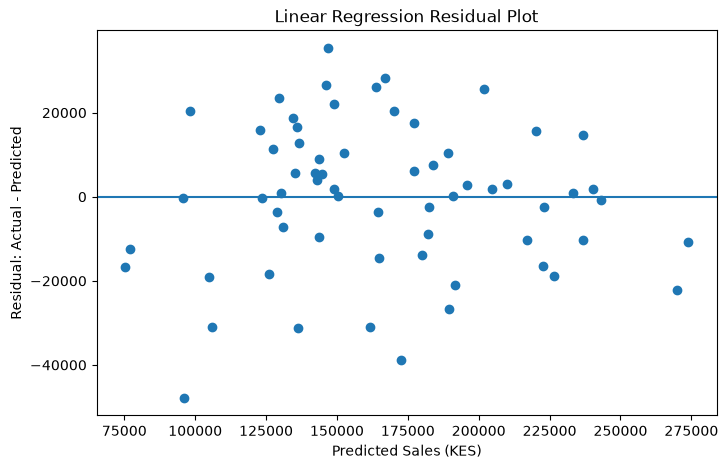

In [18]:
residuals = y_test - linear_pred
residual_df = pd.DataFrame({
"Actual": y_test.values,
"Predicted": linear_pred,
"Residual": residuals.values
})
residual_df.head()
plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()


## Interpretation: discuss whether residuals are centered around zero, whether a pattern is visible,and whether large residuals exist.



The residuals are scattered both above and below the zero line, indicating that the model sometimes overpredicts and sometimes underpredicts sales. However, the residuals are not perfectly evenly distributed, and some relatively large residuals are present. For example, one residual is approximately −48,000 KES, while several others are around +30,000 KES or below −30,000 KES. There is no strong, obvious curved pattern, although the spread of residuals suggests that prediction errors vary across observations. Overall, the plot indicates that the Linear Regression model captures the general relationship in the data reasonably well, but it makes some substantial errors for individual sales predictions.




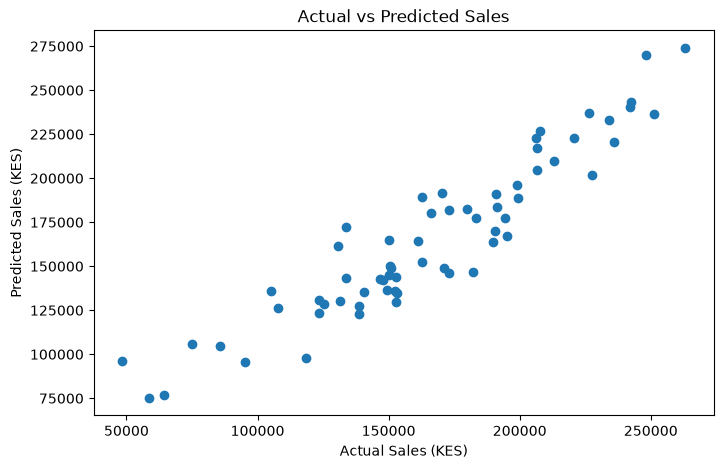

In [19]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

If predictions were perfect, points would lie close to an imaginary diagonal line where Actual =
Predicted.

In [20]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()
error_analysis.sort_values(
"AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


## Questions: Do the largest errors share characteristics? Are they concentrated in one region,segment, or category? What additional data might explain them?



The largest prediction errors occur across different regions, customer segments, and product categories, suggesting that the errors are not exclusive to one group. Nairobi and Retail customers appear several times in the top ten errors, but the results do not prove that these groups are more difficult to predict without comparing them with the overall dataset. The model both overpredicts and underpredicts sales. For example, the largest error occurs for a Nairobi Retail customer purchasing Home products, where the model overpredicts sales by approximately KES 47,860. In contrast, it underpredicts another observation's sales by approximately KES 35,379. Additional data on seasonal demand, stock availability, competitor prices, customer purchase history, product prices, store-level conditions, and special promotions could help explain these errors and improve prediction accuracy.



In [21]:
segment_errors = error_analysis.groupby(
"CustomerSegment"
).agg(
Observations=("AbsoluteError", "size"),
MAE=("AbsoluteError", "mean")
).reset_index()
segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


## Explain which segment has the highest MAE, whether sample sizes are similar, and why subgroup performance matters even when overall MAE looks acceptable.



The Retail segment has the highest MAE at approximately KES 15,560.58, meaning its predictions have the largest average absolute error among the three customer segments. Corporate has an MAE of KES 14,300.00, while SME has the lowest MAE at approximately KES 10,481.46. The sample sizes are relatively similar but not identical: Retail has 27 observations, Corporate has 19, and SME has 18. Since Retail has more observations, its MAE may be somewhat more representative, while results for Corporate and SME may be more sensitive to individual predictions. Subgroup performance matters because an acceptable overall MAE can hide larger errors for particular customer groups. Identifying these differences helps determine where the model may need improvement and ensures predictions are useful across all customer segments.



In [22]:
tree_train_pred = tree_model.predict(X_train)
print(
"Shallow Tree Training MAE:",
round(mean_absolute_error(y_train, tree_train_pred), 2)
)
print(
"Shallow Tree Test MAE:",
round(mean_absolute_error(y_test, tree_pred), 2)
)


Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


In [23]:
deep_tree = Pipeline([
("preprocess", preprocessor),
("model", DecisionTreeRegressor(
random_state=RANDOM_STATE
    ))
])
deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)
print(
"Deep Tree Training MAE:",
round(mean_absolute_error(y_train, deep_train_pred), 2)
)
print(
"Deep Tree Test MAE:",
round(mean_absolute_error(y_test, deep_test_pred), 2)
)

Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


Explain why an almost-perfect training result does not necessarily indicate a better model.

An almost-perfect training result does not necessarily indicate a better model because the model may be overfitting the training data. Overfitting occurs when a model learns the training examples too closely, including noise and unusual patterns, and therefore performs poorly on new, unseen data. A better model should generalise well to unseen data, so its performance should be evaluated using cross-validation and a separate test set. Comparing training and validation results helps identify overfitting and select a model that makes reliable predictions on new sales data.

## Part 22 – Extension Challenge
##  Try Ridge alpha values 0.1, 1, 10, and 100.
## Remove AdvertisingSpend_KES or StoreVisits, retrain Linear Regression, and explain the performance change.



I tested Ridge Regression using alpha values of 0.1, 1, 10, and 100 and compared their test MAE values. The best result was obtained with **alpha = 10**, which achieved a test MAE of approximately **KES 13,624.90**. This was better than alpha = 1 (KES 13,714.40), alpha = 0.1 (KES 13,753.36), and alpha = 100 (KES 16,922.75). Increasing alpha from 0.1 to 10 slightly improved prediction accuracy, suggesting that stronger regularisation helped the model generalise. However, alpha = 100 increased the prediction error considerably, possibly because excessive regularisation caused underfitting. Therefore, alpha = 10 was the best choice among the tested values.

In [24]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
import pandas as pd

alpha_values = [0.1, 1, 10, 100]
results = []

for alpha in alpha_values:
    # Keep the same preprocessing steps
    tuned_model = clone(ridge_model)
    tuned_model.set_params(model__alpha=alpha)

    tuned_model.fit(X_train, y_train)
    predictions = tuned_model.predict(X_test)

    results.append({
        "Alpha": alpha,
        "Test_MAE": mean_absolute_error(y_test, predictions)
    })

alpha_results = pd.DataFrame(results).sort_values("Test_MAE")
display(alpha_results)

,Alpha,Test_MAE
2,10.0,13624.901530
1,1.0,13714.400361
0,0.1,13753.355349
3,100.0,16922.745379


## Part 23 – Final Recommendation
## Write 6–8 sentences answering: Which baseline was strongest? 

The Median Baseline was the strongest baseline because it achieved a lower test MAE of KES 39,146.75 and RMSE of KES 48,649.47 than the Mean Baseline. However, both baselines performed poorly compared with the candidate regression models.

## Which candidate model performed best?

Ridge Regression with an alpha value of 10 performed best in the extension experiment, achieving the lowest test MAE of KES 13,624.90 among the tested alpha values.


 ## Did it clearly beat the baseline? 
Yes. Ridge Regression with alpha = 10 achieved a test MAE of KES 13,624.90, substantially lower than the Median Baseline MAE of KES 39,146.75. This shows that the model predicts sales much more accurately than simply using the median sales value.

 
## What does MAE mean in business terms? 
An MAE of KES 13,624.90 means the model’s sales predictions are off by about KES 13,625 on average. This helps the business understand the typical size of its prediction errors when planning sales and budgets.

## Whatdid residual analysis reveal? 

Residual analysis showed that the model sometimes overpredicts and sometimes underpredicts sales. Some observations had large errors, indicating that the model does not predict every sale accurately.


## Did performance differ by customer segment? Is there evidence ofoverfitting?
Yes. Retail had the highest MAE at KES 15,560.58, while SME had the lowest at KES 10,481.46. This indicates that the model predicted sales more accurately for SME customers than for Retail customers.

There is no strong evidence of overfitting in the original Ridge Regression model because its cross-validation and test results were similar. However, further validation is needed to confirm that the tuned model generalises well to new sales data.



## Would you deploy the model immediately? Why or why not?
No, I would not deploy the model immediately. I would first validate the selected model using cross-validation, test it on unseen data, and investigate large prediction errors to ensure it is reliable for business decisions.


## Part 24 – LimitationsState at least three limitations. Examples: small dataset, teaching/synthetic data, limitedpredictors, missing external factors, future data drift, or the fact that prediction does not imply Causation.

1. Small dataset: The dataset contains only 320 observations, which may limit how well the model generalises to new sales data.
2. Limited predictors: Important factors such as product prices, competition, seasonality, and stock availability are not included.
3. Prediction does not imply causation: The model identifies relationships between variables but cannot prove that advertising spending or discounts cause changes in sales.
4. Possible data limitations: If the dataset is synthetic or designed for teaching, its patterns may not reflect real business conditions.
5. Future data drift: Changes in customer behaviour, market conditions, or economic factors may reduce the model’s accuracy over time.



